In [66]:
import xarray as xr 
import numpy as np
from glob import glob

from scipy.signal import find_peaks

import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.pyplot as plt
import matplotlib.colors as colors

from cmcrameri import cm as cmcra
import plotting_utils

In [67]:
# importing processed dataset
path_source = '../steady_out/' #don't forget the final '/'
exp =  'TEMP'
ds_steady = xr.open_mfdataset(path_source + exp + '.nc')

path_source = '../monthly_out/' #don't forget the final '/'
exp =  'TEMP_m'
ds_monthly = xr.open_mfdataset(path_source + exp + '.nc')

In [68]:
# define lists

time_list = np.linspace(0,160,160*12) # years

depth_list = np.arange(20, 580+1, 20) # m

T0_list = np.array([2,1,0,-1,-1.9]) # °C

dzT_resto_list = (T0_list - (-1.9))/600 # °C/m

sfx_list = np.arange(0, 0.075+0.001, 0.005) # g/m^2/s

labels = ['2 °C', '1 °C', '0 °C', '-1 °C', '-1.9 °C']

colors_plot =  [cm.coolwarm(x) for x in np.linspace(1, 0, 4)]+[cmcra.lipari(0.05)]

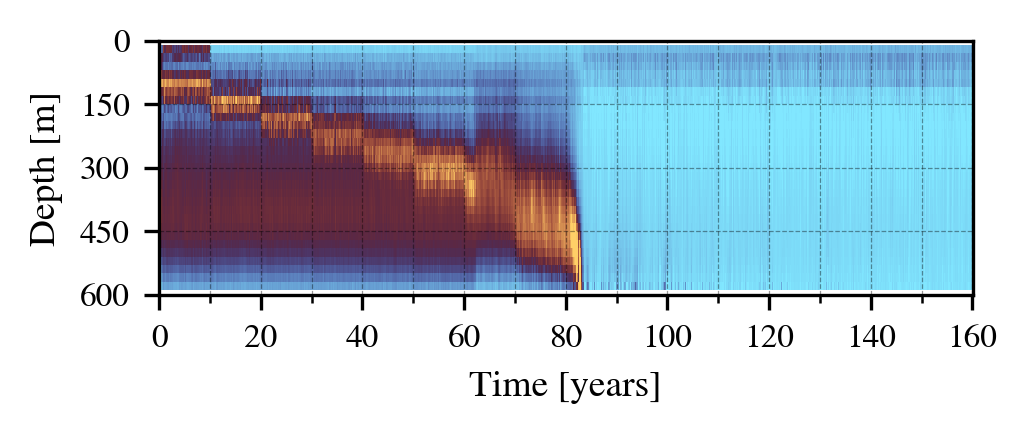

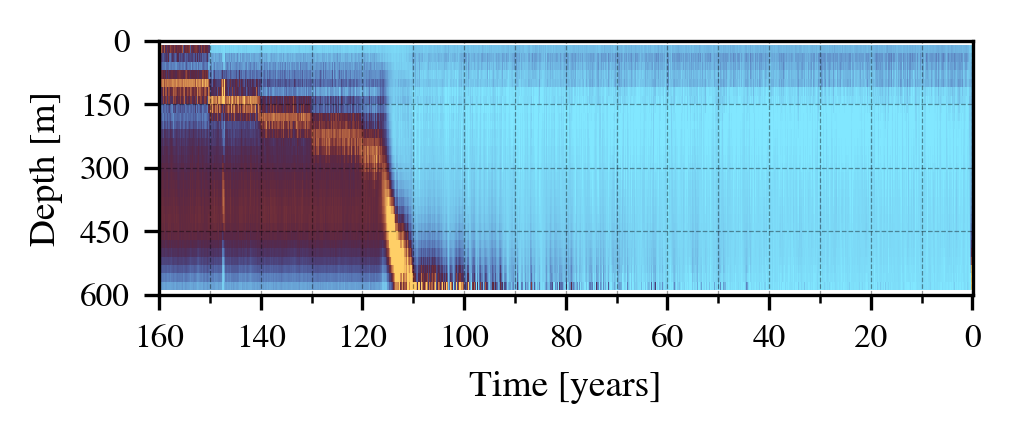

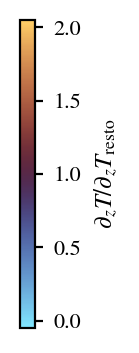

In [69]:
# TEMP1 monthly plot

TT, ZZ = np.meshgrid(time_list,depth_list)

for i, trans in zip(range(2),["wtc","ctw"]):

    dzT = ds_monthly.dzT.sel(transition=trans, T0=1)
    dzT_resto = dzT_resto_list[1]

    fig = plt.figure(figsize=(3.5,1.1),dpi=300)
    ax = plt.gca()

    #ax[i].pcolormesh(TT,ZZ,(dzT/dzT_resto).T, cmap=cmcra.managua_r,vmin=0,vmax=2)
    vmin = -0.05
    vmax = 2.05
    norm = colors.Normalize(vmin=vmin, vmax=vmax,)
    plotting = {'vmin':vmin, 'vmax':vmax, 'cmap':cmcra.managua_r,}
    cont_dzT = ax.pcolormesh(TT,ZZ,(dzT/dzT_resto).T, **plotting)

    
    from matplotlib.ticker import MultipleLocator
    ax.xaxis.set_major_locator(MultipleLocator(20)) # Major ticks → every 20 (these get labels)
    ax.xaxis.set_minor_locator(MultipleLocator(10)) # Minor ticks → every 10 (grid only)

    ax.set_yticks(np.arange(0,600+1,150))

    ax.invert_yaxis()

    ax.set_ylabel('Depth [m]')
    ax.set_xlabel('Time [years]')

    

    ax.grid(which='major', lw=0.3, c='black', alpha=0.4, ls='dashed')
    ax.grid(which='minor', lw=0.3, c='black', alpha=0.4, ls='dashed')

    if i==1:
        ax.invert_xaxis()

    plt.savefig(f'./Figure5/dzT_monthly_{trans}.png', format='png', dpi=300, bbox_inches='tight')

    plt.show()




# colorbar

fig_cb, ax_cb = plt.subplots(figsize=(5.5, 2),dpi=200)  # taller than wide

cbar = fig_cb.colorbar(
    cont_dzT,
    ax=ax_cb,
    fraction=0.15,   # controls width (smaller = thinner)
    aspect=20       # controls length/thickness ratio
)

ax_cb.remove()

cbar.set_label(r'$\partial_zT/\partial_zT_\mathrm{resto}$', fontsize=9)
cbar.ax.tick_params(labelsize=8, width=0.8, length=3)

plt.savefig(f'./Figure5/dzT_monthly_cbar.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [70]:
prof

array([-0.00119561, -0.00108108, -0.00118571, -0.00131259, -0.00137823,
       -0.00154513, -0.00158868, -0.00164401, -0.00166551, -0.00167896,
       -0.00167159, -0.00166056, -0.00163948, -0.00161745, -0.00158992,
       -0.00156274, -0.00153383, -0.00150986, -0.00149015, -0.00147608,
       -0.00146348, -0.00145501, -0.00144691, -0.00144309, -0.00144121,
       -0.00144516, -0.0014488 , -0.00146579, -0.00141565])

In [71]:
# Computing steady thermocline depth

therm_wtc = np.zeros((4,16))
therm_ctw = np.zeros((4,16))

for index, T0, dzT_resto in zip(range(4), T0_list[:4], dzT_resto_list[:4]):

    for sfx_idx in range(16):


        # managing warm-to-cold
        
        prof = ds_steady.dzT.sel(transition='wtc', T0=T0).isel(Fs=sfx_idx) - dzT_resto
        prof = prof.values[1:-1]
        peaks = find_peaks(prof,height=-0.001)

        # for T0=2°C select first peak manually
        if index==0 and sfx_idx in [2,3,4]:
            therm_wtc[index,sfx_idx] = depth_list[peaks[0][0]]
    
        elif len(peaks[0] != 0):
            arg_therm = np.argmax(peaks[1]['peak_heights'])
            
            value = depth_list[peaks[0][arg_therm]]
            therm_wtc[index,sfx_idx] = depth_list[peaks[0][arg_therm]]

        
        elif np.logical_and(len(peaks[0])==0,np.max(prof)>0):
            arg_therm = np.argmax(prof)
            therm_wtc[index,sfx_idx] = depth_list[arg_therm]

        else:
            therm_wtc[index,sfx_idx] = 600



        # managing cold-to-warm

        prof = ds_steady.dzT.sel(transition='ctw', T0=T0).isel(Fs=sfx_idx) - dzT_resto
        prof = prof.values[1:-1]
        
        peaks = find_peaks(prof,height=0)

        if index==0 and sfx_idx in [2,3,4]:
            peaks_special = find_peaks(prof,height=-0.0015)
            therm_ctw[index,sfx_idx] = depth_list[peaks_special[0][0]]

        
        
        elif len(peaks[0] != 0):
            arg_therm = np.argmax(peaks[1]['peak_heights'])
            therm_ctw[index,sfx_idx] = depth_list[peaks[0][arg_therm]]

            value = depth_list[peaks[0][arg_therm]]
            therm_ctw[index,sfx_idx] = depth_list[peaks[0][arg_therm]]

        
        elif np.logical_and(len(peaks[0])==0,np.max(prof)>0):
            arg_therm = np.argmax(prof)
            therm_ctw[index,sfx_idx] = depth_list[arg_therm]

        else:
            therm_ctw[index,sfx_idx] = 600



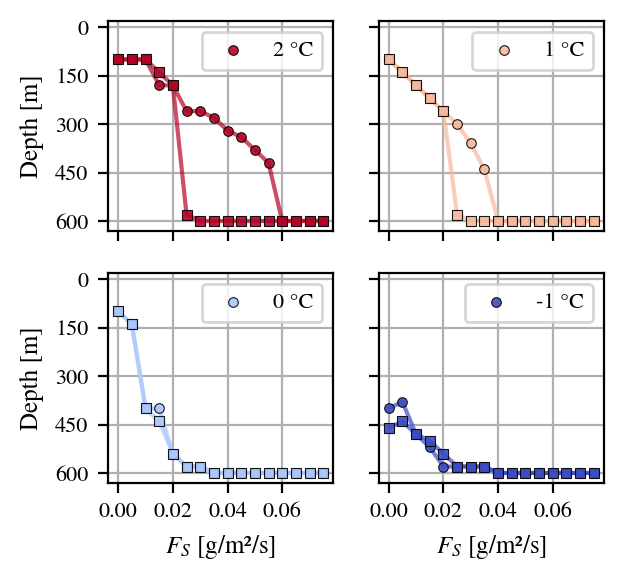

In [72]:
# TEMP steady dzT plot

colors_plot =  [cm.coolwarm(x) for x in np.linspace(1, 0, 4)]

fig, ax = plt.subplots(2,2,figsize=(3.2,3),sharex=True,sharey=True, dpi=200)

for index in range(4):

    i = index//2
    j = index%2

    ax[i,j].plot(sfx_list, therm_wtc[index], color=colors_plot[index], alpha=0.7,)
    ax[i,j].plot(sfx_list, therm_ctw[index], color=colors_plot[index], alpha=0.7,)



for index in range(4):

    i = index//2
    j = index%2

    ax[i,j].scatter(sfx_list, therm_wtc[index], marker='o', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=12, alpha=0.9,zorder=2, label=labels[index])
    ax[i,j].scatter(sfx_list, therm_ctw[index], marker='s', edgecolors='black', facecolors=colors_plot[index], lw=0.4, s=12, alpha=0.9,zorder=2)


    ax[i,j].set_xticks(np.arange(0, 0.075, 0.02))
    ax[i,j].set_yticks(np.arange(0,600+1,150))

    ax[i,j].grid()

    ax[i,j].legend()


for i in range(2):
    ax[i,0].set_ylabel('Depth [m]')

for j in range(2):
    ax[1,j].set_xlabel(r'$F_S$ [g/m²/s]')

ax[0,0].invert_yaxis()

ax[0,0].set_ylim(630,-20)

plt.savefig('./Figure5/dzT_steady_hyst.pdf',format='pdf',bbox_inches='tight')

plt.show()

